# 7. Evaluación ampliada y robustez

Este capítulo cubre la sección 6.6 de la guía (Tabla 4). Primero, los 10 modelos en tres conjuntos de datos públicos adicionales y la
comparación entre conjuntos. Después, en Home Credit, los estudios de robustez: sensibilidad a hiperparámetros, semillas, ruido,
escalabilidad, desbalance, cambio de distribución, calibración, incertidumbre conforme y análisis de errores por subgrupo. Todo lo de
robustez es **exploratorio** (protocolo, sec. 8.5): describe el comportamiento de los modelos pero no sustenta R3.

Los cálculos están en `experiments/e13_datasets_adicionales.py`, `e14_robustez.py` y `e15_estadistica_final.py`; este cuaderno lee sus
resultados (`resultados_e4/`).

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd()                       # raiz del repositorio (sin rutas absolutas)
assert (RAIZ / "resultados_e4" / "f7_estadistica" / "resumen.json").is_file(), "Ejecute este cuaderno desde la raiz del repositorio"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
NOMBRE = {"elar": "ELAR-R", "xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM", "logistica": "Logistica",
          "svm": "SVM", "random_forest": "Random forest", "arbol": "Arbol", "knn": "KNN", "naive_bayes": "Naive Bayes"}
CONJ = {"german_credit": "German credit", "taiwan_default": "Taiwan default", "bank_marketing": "Bank marketing", "home_credit": "Home Credit"}
CABEZA = ["elar", "xgboost", "catboost", "lightgbm"]
COLOR = {"elar": "#C44E52", "xgboost": "#4C72B0", "catboost": "#55A868", "lightgbm": "#8172B2"}
COLOR2 = {**COLOR, "logistica": "#DD8452", "random_forest": "#937860", "naive_bayes": "#8C8C8C", "svm": "#DA8BC3",
          "arbol": "#CCB974", "knn": "#64B5CD"}
F7, F6 = RAIZ / "resultados_e4" / "f7_estadistica", RAIZ / "resultados_e4" / "f6_robustez"
res = json.loads((F7 / "resumen.json").read_text(encoding="utf-8"))

## 7.1 Conjuntos de datos adicionales

Los conjuntos se eligieron antes de ver cualquier resultado (protocolo, sec. 8.3) en OpenML {cite}`vanschoren2014openml`: públicos,
de clasificación binaria en el dominio financiero y con distinto tamaño, dimensión y desbalance.

| Conjunto | OpenML | Filas | Variables | Positivos | Por qué |
|---|---|---|---|---|---|
| German credit | 31 | 1,000 | 20 mixtas | 30 % | pequeño y muy categórico |
| Taiwan default | 42477 | 30,000 | 23 | 22 % | historial de pagos con estructura secuencial |
| Bank marketing | 1461 | 45,211 | 16 | 11.7 % | grande, desbalanceado, otro problema bancario |

**Mismas condiciones para los 10 modelos:** 5 repeticiones de validación cruzada estratificada de 2 pliegues (semillas 0–4), es decir
10 mediciones externas por modelo; dentro de cada pliegue, búsqueda TPE con 20 evaluaciones y **3 pliegues internos** para todos (la
regla de recorte a 80/20 del protocolo no se usó); el mismo preprocesamiento aprendido dentro del pliegue. Ninguna corrida falló.

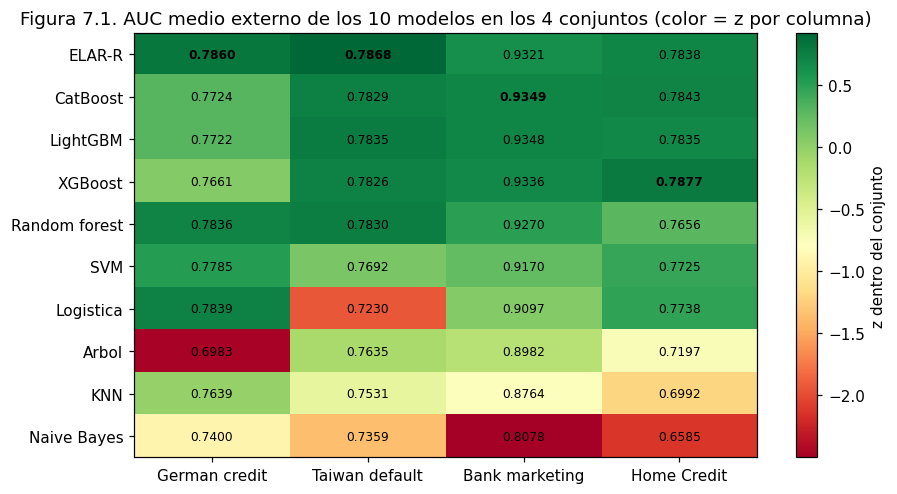

,German credit,Taiwan default,Bank marketing,Home Credit,rango medio
ELAR-R,0.7860,0.7868,0.9321,0.7838,2.25
CatBoost,0.7724,0.7829,0.9349,0.7843,3.00
LightGBM,0.7722,0.7835,0.9348,0.7835,3.50
XGBoost,0.7661,0.7826,0.9336,0.7877,4.00
Random forest,0.7836,0.7830,0.9270,0.7656,4.50
SVM,0.7785,0.7692,0.9170,0.7725,5.50
Logistica,0.7839,0.7230,0.9097,0.7738,6.00
Arbol,0.6983,0.7635,0.8982,0.7197,8.25
KNN,0.7639,0.7531,0.8764,0.6992,8.50
Naive Bayes,0.7400,0.7359,0.8078,0.6585,9.50


In [2]:
M = pd.read_csv(F7 / "matriz_auc_conjuntos.csv", index_col=0).T.rename(index=NOMBRE, columns=CONJ)
M["rango medio"] = pd.Series(res["entre_conjuntos"]["rangos_medios"]).rename(index=NOMBRE)
M = M.sort_values("rango medio")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
V = M[list(CONJ.values())]
Z = (V - V.mean()) / V.std()
im = ax.imshow(Z.values, cmap="RdYlGn", aspect="auto")
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        ax.text(j, i, f"{V.iat[i, j]:.4f}", ha="center", va="center", fontsize=8,
                fontweight="bold" if V.iat[i, j] == V.iloc[:, j].max() else "normal")
ax.set_xticks(range(V.shape[1]), V.columns); ax.set_yticks(range(V.shape[0]), V.index); ax.grid(False)
ax.set(title="Figura 7.1. AUC medio externo de los 10 modelos en los 4 conjuntos (color = z por columna)")
plt.colorbar(im, ax=ax, label="z dentro del conjunto"); plt.tight_layout(); plt.show()
M.round(4)

**Lectura de la figura 7.1.** Ningún modelo gana en todos los conjuntos. ELAR-R es el mejor en German credit y Taiwan default; CatBoost
en Bank marketing; XGBoost en Home Credit. Los modelos de boosting y ELAR-R forman el grupo de cabeza en todos, mientras que Naive Bayes,
KNN y el árbol quedan siempre abajo. La regresión logística es casi tan buena como ELAR-R en German (pocos datos, relaciones casi lineales)
y la peor de los modelos razonables en Taiwan, donde importan las interacciones del historial de pagos.

## 7.2 Hipótesis H2: ¿es ELAR-R consistente en los conjuntos adicionales?

Criterio 6.4.4 de la guía (H2 del protocolo, sec. 8.1): ELAR-R debe tener el mejor AUC medio en al menos 2 de 3 conjuntos y **no ser
significativamente peor** que el mejor benchmark en ninguno. Se usa la t corregida de Nadeau-Bengio y Wilcoxon sobre las 10 mediciones,
con Holm dentro de cada conjunto, δ de Cliff y DeLong por repetición.

In [3]:
P = pd.read_csv(F7 / "pruebas_por_conjunto.csv")
filas = []
for conj, r in res["conjuntos"].items():
    mejor = r["mejor_benchmark"]
    p = P[(P["conjunto"] == conj) & (P["benchmark"] == mejor)].iloc[0]
    filas.append({"conjunto": CONJ[conj], "ELAR-R": r["auc_medio"]["elar"], "mejor benchmark": NOMBRE[mejor],
                  "AUC mejor benchmark": r["auc_medio"][mejor], "diferencia": p["dif_media"], "IC 95 % BCa (rep. 0)": p["ic95_bca_rep0"],
                  "p Nadeau-Bengio (Holm)": p["p_nb_holm"], "p Wilcoxon (Holm)": p["p_wilcoxon_holm"],
                  "delta de Cliff": f"{p['cliff']:+.1f} ({p['cliff_magnitud']})",
                  "DeLong: repeticiones a favor / en contra": f"{p['delong_rep_sig_favor_elar']} / {p['delong_rep_sig_contra_elar']}",
                  "ELAR-R mejor": r["elar_es_mejor"], "significativamente peor": r["elar_significativamente_peor_que_mejor"]})
H2 = pd.DataFrame(filas).set_index("conjunto")
h = res["H2"]
print(f"ELAR-R mejor en {h['elar_mejor_en']} de {h['conjuntos_evaluados']}; significativamente peor en {h['elar_significativamente_peor_en']} "
      f"-> H2 {'SE CUMPLE' if h['cumple'] else 'NO SE CUMPLE'}")
H2.round(4)

ELAR-R mejor en 2 de 3; significativamente peor en 1 -> H2 NO SE CUMPLE


,ELAR-R,mejor benchmark,AUC mejor benchmark,diferencia,IC 95 % BCa (rep. 0),p Nadeau-Bengio (Holm),p Wilcoxon (Holm),delta de Cliff,DeLong: repeticiones a favor / en contra,ELAR-R mejor,significativamente peor
conjunto,,,,,,,,,,,
German credit,0.7860,Logistica,0.7839,0.0021,"[0.0146, 0.0537]",1.0000,1.0000,+0.2 (pequeno),3 / 0,True,False
Taiwan default,0.7868,LightGBM,0.7835,0.0034,"[0.0010, 0.0043]",0.2474,0.0254,+0.8 (grande),5 / 0,True,False
Bank marketing,0.9321,CatBoost,0.9349,-0.0028,"[-0.0038, -0.0017]",0.0686,0.0273,-1.0 (grande),0 / 5,False,True


**Lectura de la tabla 7.2.** ELAR-R cumple la primera parte (es el mejor en 2 de 3), pero no la segunda: en Bank marketing CatBoost es
mejor en las 10 particiones (δ de Cliff = −1), con IC BCa enteramente negativo, Wilcoxon significativo tras Holm y DeLong significativo
en contra en las 5 repeticiones. Nadeau-Bengio no llega a 0.05 (es la prueba más conservadora con 10 mediciones), pero la regla
declarada pide que cualquiera de las dos rechace. **H2 se rechaza.** En German la ventaja de ELAR-R no es significativa (1,000 filas,
mucha varianza); en Taiwan es pequeña (+0.003) pero aparece en todas las particiones.

## 7.3 Comparación entre conjuntos

Friedman con N = 4 conjuntos y k = 10 modelos: chi2 = 24.8, p = 0.0032; Iman-Davenport F = 6.66, p = 5.6e-05; CD de Nemenyi = 6.77


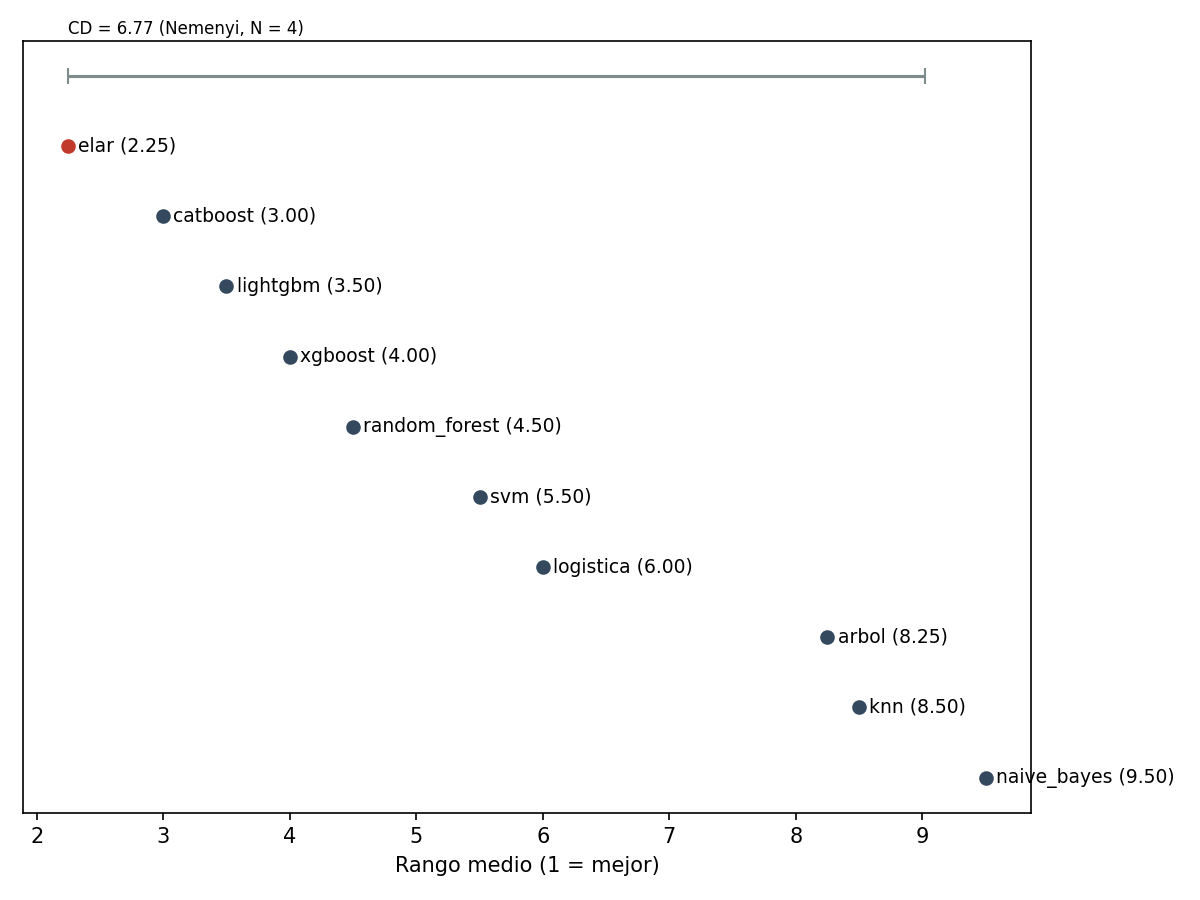

,rango_elar,rango_modelo,z,p,p_holm,P(ELAR-R mejor),P(equivalente),P(benchmark mejor)
modelo,,,,,,,,
CatBoost,2.25,3.00,0.350,0.726,1.000,0.690,0.155,0.156
LightGBM,2.25,3.50,0.584,0.559,1.000,0.690,0.155,0.156
XGBoost,2.25,4.00,0.817,0.414,1.000,0.690,0.076,0.234
Random forest,2.25,4.50,1.051,0.293,1.000,0.993,0.007,0.000
SVM,2.25,5.50,1.518,0.129,0.645,0.993,0.007,0.000
Logistica,2.25,6.00,1.752,0.080,0.479,0.993,0.007,0.000
Arbol,2.25,8.25,2.803,0.005,0.035,0.993,0.007,0.000
KNN,2.25,8.50,2.919,0.004,0.028,0.993,0.007,0.000
Naive Bayes,2.25,9.50,3.386,0.001,0.006,0.993,0.007,0.000


In [4]:
e = res["entre_conjuntos"]; f = e["friedman"]
print(f"Friedman con N = {f['N']} conjuntos y k = {f['k']} modelos: chi2 = {f['chi2']:.1f}, p = {f['p']:.4f}; "
      f"Iman-Davenport F = {f['F_iman_davenport']:.2f}, p = {f['p_F']:.1e}; CD de Nemenyi = {e['cd_nemenyi']:.2f}")
ph = pd.read_csv(F7 / "posthoc_entre_conjuntos.csv")
ph["bayes"] = ph["bayes"].map(lambda s: eval(s, {}))           # dict guardado como texto por e15
ph["P(ELAR-R mejor)"] = ph["bayes"].map(lambda b: b["p_a_mejor"])
ph["P(equivalente)"] = ph["bayes"].map(lambda b: b["p_equivalente"])
ph["P(benchmark mejor)"] = ph["bayes"].map(lambda b: b["p_b_mejor"])
ph["modelo"] = ph["modelo"].map(NOMBRE)
display(Image(filename=str(F7 / "diagrama_cd.png"), width=620))
ph.drop(columns="bayes").set_index("modelo").sort_values("rango_modelo").round(3)

**Lectura de la figura 7.2 y la tabla 7.3.** Con los 4 conjuntos, ELAR-R tiene el mejor rango medio (2.25), seguido de CatBoost (3.0),
LightGBM (3.5) y XGBoost (4.0). Friedman e Iman-Davenport rechazan que los 10 modelos sean equivalentes. Con solo 4 conjuntos, sin embargo,
la diferencia crítica es enorme (6.77 rangos): las comparaciones con Holm solo separan a ELAR-R de Naive Bayes, KNN y el árbol. La prueba
bayesiana da una probabilidad de ≈ 0.69 de que ELAR-R sea mejor que cada modelo de boosting, lejos de una conclusión firme. El mejor rango
medio **no** es evidencia de superioridad {cite}`demsar2006statistical`.

## 7.4 Robustez en Home Credit: diseño

Los estudios que exigen reentrenar se hicieron con **los 10 modelos y el mismo protocolo**: partición del pliegue externo 0, submuestra
estratificada de 60,000 filas para entrenar (por el costo de ELAR-R y SVM) y la validación externa completa (≈ 49,200 filas) para evaluar.
Por eso los AUC de esta sección (≈ 0.77 para los mejores) son menores que los de la tabla del capítulo 3. Los estudios sin reentreno
(calibración, conformal, subgrupos, cambio de distribución) usan las predicciones de los modelos finales sobre la prueba.

In [5]:
R = pd.read_csv(F6 / "reentreno.csv").drop_duplicates(["estudio", "modelo", "variable", "valor"])  # una fila por estudio
base = R[(R["estudio"] == "semillas") & (R["valor"] == 0)].set_index("modelo")["auc"]
sem = R[R["estudio"] == "semillas"].groupby("modelo")["auc"].agg(["count", "mean", "std"])
sens = R[R["estudio"] == "sensibilidad"].groupby(["modelo", "variable"])["auc"].agg(lambda v: v.max() - v.min()).unstack()
t74 = pd.DataFrame({"AUC base (60k)": base, "semillas": sem["count"], "media 10 semillas": sem["mean"], "de entre semillas": sem["std"],
                    "rango sensibilidad (max)": sens.max(axis=1)}).rename(index=NOMBRE).sort_values("AUC base (60k)", ascending=False)
print("Hiperparametros de la sensibilidad (5 valores cada uno, alrededor de la configuracion):")
print(R[R["estudio"] == "sensibilidad"].groupby("modelo")["variable"].unique().map(", ".join).rename(index=NOMBRE).to_string())
t74.round(4)

Hiperparametros de la sensibilidad (5 valores cada uno, alrededor de la configuracion):
modelo
Arbol                 max_depth, min_samples_leaf
CatBoost                     learning_rate, depth
ELAR-R           tasa_profundo, min_muestras_hoja
KNN                      n_vecinos, n_componentes
LightGBM                learning_rate, num_leaves
Logistica                                       C
Naive Bayes                         var_smoothing
Random forest      max_features, min_samples_leaf
SVM                                             C
XGBoost                  learning_rate, max_depth


,AUC base (60k),semillas,media 10 semillas,de entre semillas,rango sensibilidad (max)
modelo,,,,,
XGBoost,0.7715,10,0.7722,0.0011,0.0025
ELAR-R,0.7676,10,0.7685,0.0005,0.0021
CatBoost,0.7661,10,0.7680,0.0016,0.0073
LightGBM,0.7646,10,0.7649,0.0008,0.0211
Logistica,0.7608,1,0.7608,NaN,0.0068
SVM,0.7584,10,0.7572,0.0008,0.0050
Random forest,0.7514,10,0.7521,0.0005,0.0106
Arbol,0.6979,1,0.6979,NaN,0.0434
KNN,0.6895,1,0.6895,NaN,0.0257


**Lectura de la tabla 7.4 (semillas y sensibilidad).** Con 10 semillas, ELAR-R es, junto con random forest, el más estable de los modelos
estocásticos: su desviación estándar (0.0005) es la mitad de la de XGBoost y un tercio de la de CatBoost. También es el menos sensible a sus
hiperparámetros: moviendo la tasa de la vista profunda y el tamaño mínimo de hoja en 5 valores cada uno, el AUC cambia como mucho 0.002,
frente a 0.021 de LightGBM (muy sensible a `num_leaves`) , 0.026 de KNN (mejora de forma sostenida al
aumentar el número de vecinos) y 0.043 del árbol, el más sensible. Los modelos deterministas (logística, árbol, KNN, Naive Bayes) se reportan con
una sola semilla. La sensibilidad de KNN se hizo en una segunda corrida: en la primera se omitió por un nombre de parámetro mal escrito en el script,
que se corrigió sin cambiar nada más (`CORRER_LIBRO_E4.bat` la ejecuta antes de este capítulo).

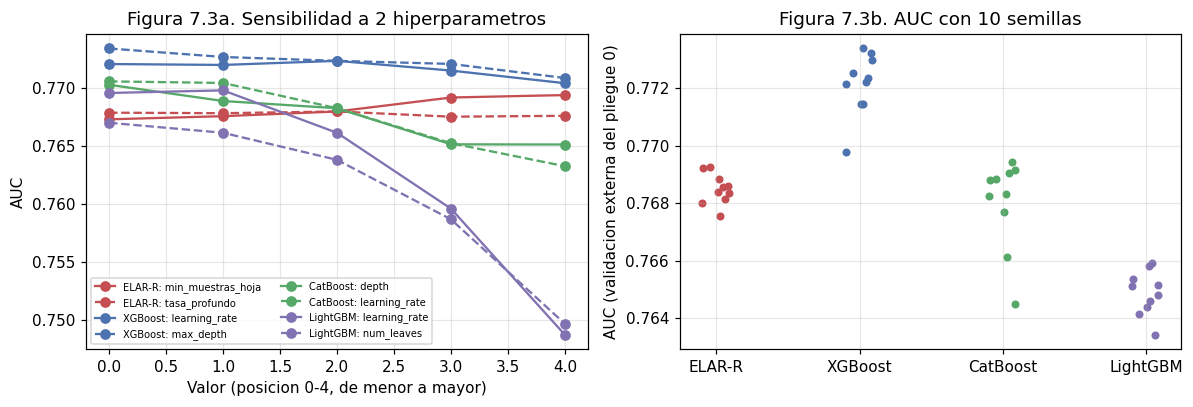

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m in CABEZA:
    s = R[(R["estudio"] == "sensibilidad") & (R["modelo"] == m)]
    for j, (v, g) in enumerate(s.groupby("variable")):
        g = g.sort_values("valor")
        ax[0].plot(range(len(g)), g["auc"].to_numpy(), marker="o", color=COLOR[m], ls="-" if j == 0 else "--",
                   label=f"{NOMBRE[m]}: {v}")
ax[0].set(title="Figura 7.3a. Sensibilidad a 2 hiperparametros", xlabel="Valor (posicion 0-4, de menor a mayor)", ylabel="AUC")
ax[0].legend(fontsize=6.5, ncol=2)
for m in CABEZA:
    v = R[(R["estudio"] == "semillas") & (R["modelo"] == m)]["auc"]
    ax[1].scatter(np.full(len(v), CABEZA.index(m)) + np.random.default_rng(0).uniform(-0.1, 0.1, len(v)), v, color=COLOR[m], s=18)
ax[1].set_xticks(range(4), [NOMBRE[m] for m in CABEZA])
ax[1].set(title="Figura 7.3b. AUC con 10 semillas", ylabel="AUC (validacion externa del pliegue 0)")
plt.tight_layout(); plt.show()

## 7.5 Ruido en entradas y etiquetas

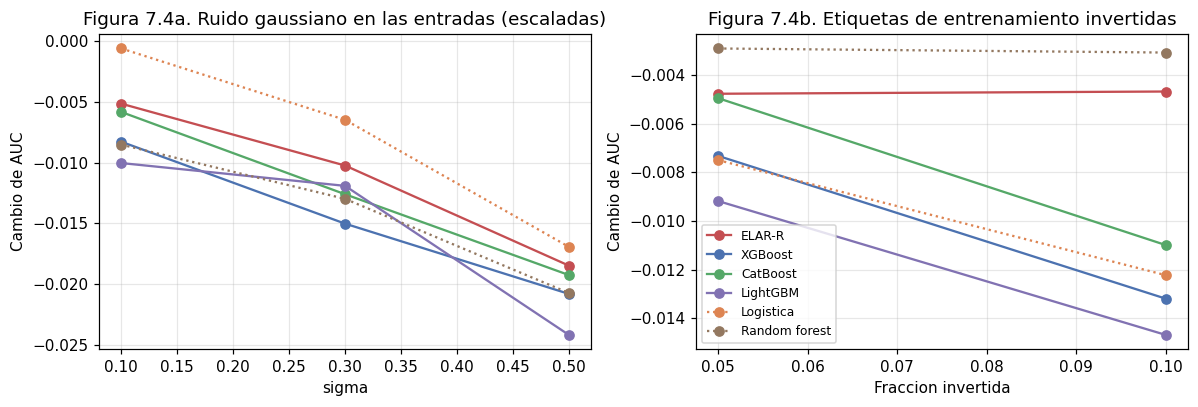

variable      etiquetas_invertidas         sigma_entradas                
valor                         0.05    0.10           0.10    0.30    0.50
modelo                                                                   
Arbol                       0.0002 -0.0123        -0.0051 -0.0106 -0.0166
CatBoost                   -0.0049 -0.0110        -0.0058 -0.0126 -0.0192
ELAR-R                     -0.0048 -0.0047        -0.0052 -0.0102 -0.0185
KNN                        -0.0123 -0.0217         0.0021 -0.0014 -0.0028
LightGBM                   -0.0092 -0.0147        -0.0100 -0.0119 -0.0242
Logistica                  -0.0075 -0.0122        -0.0006 -0.0065 -0.0169
Naive Bayes                -0.0096 -0.0218         0.0003  0.0018  0.0042
Random forest              -0.0029 -0.0031        -0.0085 -0.0130 -0.0207
SVM                        -0.0119 -0.0174        -0.0017 -0.0060 -0.0175
XGBoost                    -0.0073 -0.0132        -0.0083 -0.0150 -0.0208

In [7]:
ru = R[R["estudio"] == "ruido"].copy()
ru["caida"] = ru["auc"] - ru["modelo"].map(base)
tab = ru.pivot_table(index="modelo", columns=["variable", "valor"], values="caida").rename(index=NOMBRE)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m in CABEZA + ["logistica", "random_forest"]:
    for k, var in enumerate(["sigma_entradas", "etiquetas_invertidas"]):
        g = ru[(ru["modelo"] == m) & (ru["variable"] == var)].sort_values("valor")
        ax[k].plot(g["valor"], g["caida"], marker="o", color=COLOR2[m], ls="-" if m in CABEZA else ":", label=NOMBRE[m])
ax[0].set(title="Figura 7.4a. Ruido gaussiano en las entradas (escaladas)", xlabel="sigma", ylabel="Cambio de AUC")
ax[1].set(title="Figura 7.4b. Etiquetas de entrenamiento invertidas", xlabel="Fraccion invertida", ylabel="Cambio de AUC")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
tab.round(4)

**Lectura de la figura 7.4.** Con ruido en las entradas los modelos buenos pierden de forma parecida (0.017–0.024 de AUC con σ = 0.5;
LightGBM es el más afectado); KNN y Naive Bayes casi no cambian porque ya eran débiles. Con etiquetas invertidas la diferencia es clara:
con el 10 % de etiquetas cambiadas ELAR-R pierde 0.005 y random forest 0.003, mientras que XGBoost, CatBoost y LightGBM pierden
0.011–0.015, unas tres veces más. La explicación probable es que los dos promedian: random forest promedia árboles independientes y
ELAR-R combina tres vistas con pesos aprendidos fuera de muestra, y su vista lineal no puede memorizar etiquetas aisladas. El boosting,
en cambio, persigue los errores y termina ajustando las etiquetas cambiadas.

## 7.6 Escalabilidad: tamaño de muestra y número de variables

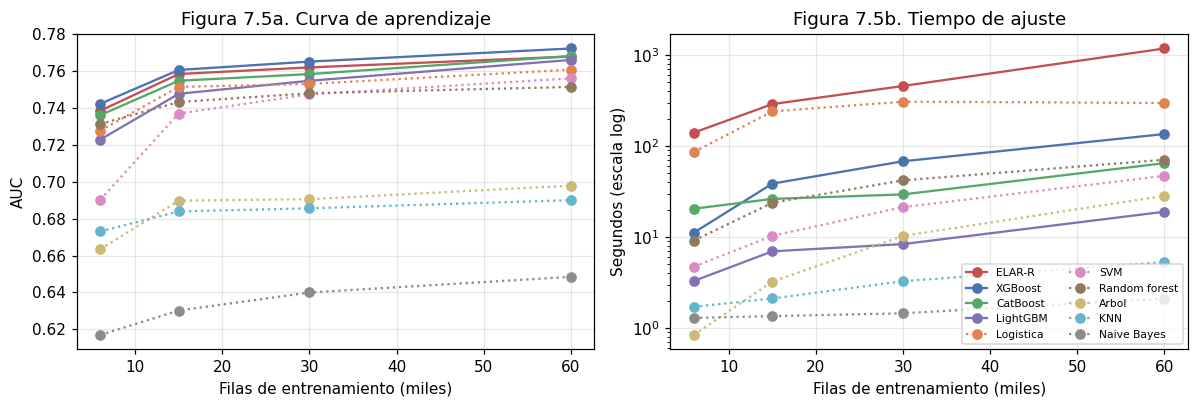

auc         segundos        
p_entrada         187     375      187     375
modelo                                        
Arbol          0.6809  0.6547     3.50    6.88
CatBoost       0.7388  0.7396    21.78   37.05
ELAR-R         0.7399  0.7395   300.80  496.24
KNN            0.6791  0.6760     3.26    3.87
LightGBM       0.7379  0.7377     5.54    8.71
Logistica      0.7315  0.7243    32.74  211.45
Naive Bayes    0.6325  0.6343     0.56    1.07
Random forest  0.7290  0.7192    56.98   67.31
SVM            0.7327  0.7246    38.63   44.84
XGBoost        0.7423  0.7399    16.39   38.63

In [8]:
mu = R[R["estudio"] == "muestra"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m in mu["modelo"].unique():
    g = mu[(mu["modelo"] == m) & (mu["variable"] == "fraccion_n")].sort_values("n_entreno")
    kw = dict(marker="o", color=COLOR2[m], ls="-" if m in CABEZA else ":", label=NOMBRE[m])
    ax[0].plot(g["n_entreno"] / 1000, g["auc"], **kw)
    ax[1].plot(g["n_entreno"] / 1000, g["segundos"], **kw)
ax[0].set(title="Figura 7.5a. Curva de aprendizaje", xlabel="Filas de entrenamiento (miles)", ylabel="AUC")
ax[1].set(title="Figura 7.5b. Tiempo de ajuste", xlabel="Filas de entrenamiento (miles)", ylabel="Segundos (escala log)", yscale="log")
ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
fp = mu[mu["variable"] == "fraccion_p"].pivot_table(index="modelo", columns="p_entrada", values=["auc", "segundos"])
fp.rename(index=NOMBRE).round(4)

**Lectura de la figura 7.5.** Todos los modelos siguen mejorando de 30,000 a 60,000 filas, así que con más datos (el desarrollo completo
tiene 246,008) el orden se mantiene y los AUC suben, como se ve en el capítulo 3. El costo es el punto débil de ELAR-R: crece casi
linealmente con $n$ y es el más lento (≈ 20 min con 60,000 filas, frente a ≈ 2 min de XGBoost y 20 s de LightGBM). La tabla muestra el
efecto de usar solo una fracción de las 750 columnas: con el 25 % o el 50 % de las variables al azar todos pierden mucho AUC (se pierden
las EXT_SOURCE con frecuencia), y el tiempo baja de forma más o menos proporcional.

## 7.7 Desbalance

In [9]:
de = R[R["estudio"] == "desbalance"].copy()
de["caida"] = de["auc"] - de["modelo"].map(base)
de.pivot_table(index="modelo", columns="valor", values="caida").rename(index=NOMBRE, columns={2.0: "prevalencia / 2", 4.0: "prevalencia / 4"}).sort_values("prevalencia / 4", ascending=False).round(4)

valor,prevalencia / 2,prevalencia / 4
modelo,,
Random forest,-0.0016,-0.0116
XGBoost,-0.0043,-0.0140
ELAR-R,-0.0024,-0.0149
CatBoost,-0.0020,-0.0202
Arbol,-0.0041,-0.0213
LightGBM,-0.0106,-0.0245
KNN,-0.0114,-0.0289
SVM,-0.0078,-0.0299
Logistica,-0.0046,-0.0301


**Lectura de la tabla 7.7.** Al quitar positivos del entrenamiento hasta dejar la mitad o la cuarta parte de la prevalencia (4 % y 2 %),
todos pierden AUC, sobre todo con la cuarta parte. Random forest, CatBoost y ELAR-R son los que menos pierden con la mitad; con la cuarta parte
ELAR-R pierde lo mismo que XGBoost (≈ 0.015) y menos que CatBoost y LightGBM. Los lineales y Naive Bayes son los más afectados.

## 7.8 Cambio de distribución

In [10]:
D = pd.read_csv(F6 / "distribucion.csv").set_index("modelo").rename(index=NOMBRE)
D[["auc_externo_media", "auc_externo_de", "auc_prueba", "degradacion", "auc_prueba_Cash loans", "auc_prueba_Revolving loans"]].sort_values("auc_prueba", ascending=False).round(4)

,auc_externo_media,auc_externo_de,auc_prueba,degradacion,auc_prueba_Cash loans,auc_prueba_Revolving loans
modelo,,,,,,
XGBoost,0.7877,0.0040,0.7902,0.0024,0.7904,0.7724
CatBoost,0.7843,0.0047,0.7898,0.0056,0.7905,0.7668
ELAR-R,0.7838,0.0038,0.7871,0.0033,0.7874,0.7685
LightGBM,0.7835,0.0035,0.7867,0.0032,0.7871,0.7665
Logistica,0.7738,0.0034,0.7765,0.0026,0.7770,0.7543
SVM,0.7725,0.0034,0.7753,0.0028,0.7760,0.7497
Random forest,0.7657,0.0042,0.7694,0.0037,0.7703,0.7483
Arbol,0.7195,0.0046,0.7253,0.0058,0.7260,0.7099
KNN,0.6993,0.0018,0.7045,0.0052,0.7051,0.6798


**Lectura de la tabla 7.8.** De la validación externa a la prueba ningún modelo se degrada (salvo Naive Bayes, −0.001); al contrario, la
prueba sale entre 0.002 y 0.006 por encima, porque el modelo final se entrena con todo el desarrollo. La partición es aleatoria (AUC adversarial 0.499, cap. 2), así
que no hay un cambio de distribución real entre desarrollo y prueba; el corrimiento que sí existe es entre subpoblaciones. Los créditos
rotativos son más difíciles de ordenar que los de efectivo para todos los modelos (≈ 0.77 frente a ≈ 0.79 en la prueba).

## 7.9 Calibración

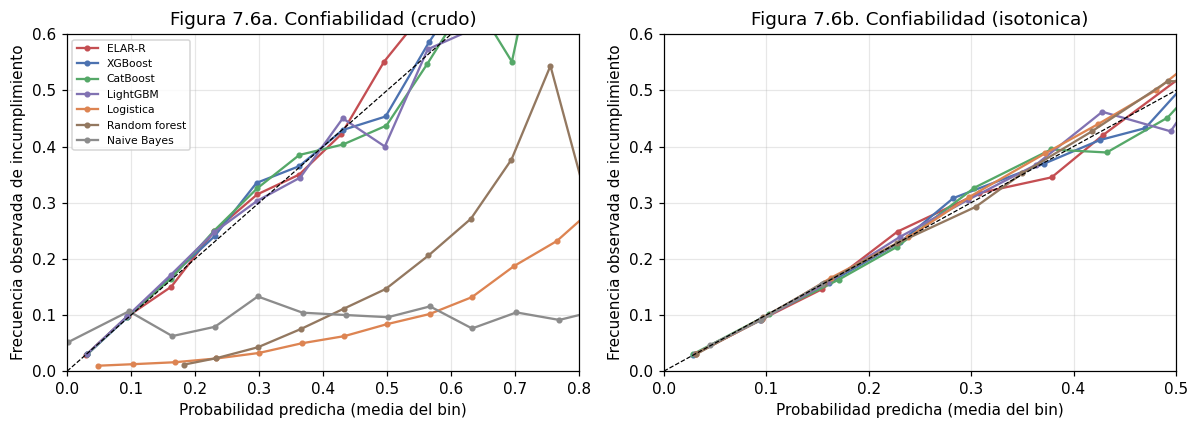

ECE con 15 bins en la prueba (Platt e isotonica ajustadas con las predicciones fuera de muestra):


variante,crudo,platt,isotonica,Brier (isotonica)
modelo,,,,
XGBoost,0.0033,0.0220,0.0023,0.0653
LightGBM,0.0037,0.0226,0.0022,0.0657
ELAR-R,0.0040,0.0033,0.0038,0.0657
CatBoost,0.0041,0.0219,0.0035,0.0654
Arbol,0.0059,0.0140,0.0035,0.0697
KNN,0.0092,0.0099,0.0011,0.0706
Random forest,0.2658,0.0054,0.0015,0.0673
Naive Bayes,0.3162,0.0004,0.0022,0.0724
Logistica,0.3248,0.0027,0.0017,0.0668


In [11]:
K = pd.read_csv(F6 / "calibracion.csv")
tabla_ece = K.pivot(index="modelo", columns="variante", values="ece")[["crudo", "platt", "isotonica"]].rename(index=NOMBRE)
tabla_ece["Brier (isotonica)"] = K[K["variante"] == "isotonica"].set_index("modelo")["brier"].rename(index=NOMBRE)
cu = pd.read_csv(F6 / "curvas_calibracion.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, var in enumerate(["crudo", "isotonica"]):
    for m in CABEZA + ["logistica", "random_forest", "naive_bayes"]:
        g = cu[(cu["modelo"] == m) & (cu["variante"] == var)]
        if len(g):
            ax[k].plot(g["p_media"], g["frecuencia"], marker=".", color=COLOR2[m], label=NOMBRE[m])
    ax[k].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[k].set(title=f"Figura 7.6{'ab'[k]}. Confiabilidad ({var})", xlabel="Probabilidad predicha (media del bin)",
              ylabel="Frecuencia observada de incumplimiento", xlim=(0, 0.8 if k == 0 else 0.5), ylim=(0, 0.6))
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print("ECE con 15 bins en la prueba (Platt e isotonica ajustadas con las predicciones fuera de muestra):")
tabla_ece.sort_values("crudo").round(4)

**Lectura de la figura 7.6 y la tabla 7.9.** Los modelos de boosting y ELAR-R salen bien calibrados sin hacer nada (ECE ≈ 0.003–0.004)
{cite}`guo2017calibration`. La logística y el random forest, entrenados con `class_weight`, y Naive Bayes dan probabilidades muy infladas
(ECE de 0.27 a 0.32): ordenan bien pero sus probabilidades no se pueden leer como riesgo. La calibración isotónica, ajustada con las
predicciones fuera de muestra, deja a todos por debajo de 0.004. El SVM no da probabilidades crudas; Platt e isotónica las construyen.
En el dashboard se muestra la probabilidad isotónica.

## 7.10 Incertidumbre: predicción conforme

In [12]:
Q = pd.read_csv(F6 / "conformal.csv").set_index("modelo").rename(index=NOMBRE)
Q[["nominal", "cobertura", "cobertura_clase1", "cobertura_clase0", "tamano_medio", "dobles", "vacios"]].sort_values("tamano_medio").round(3)

,nominal,cobertura,cobertura_clase1,cobertura_clase0,tamano_medio,dobles,vacios
modelo,,,,,,,
CatBoost,0.9,0.893,0.890,0.893,1.436,0.436,0.0
ELAR-R,0.9,0.884,0.895,0.883,1.438,0.438,0.0
XGBoost,0.9,0.902,0.896,0.902,1.461,0.461,0.0
LightGBM,0.9,0.904,0.898,0.904,1.465,0.465,0.0
SVM,0.9,0.894,0.903,0.893,1.475,0.475,0.0
Logistica,0.9,0.906,0.906,0.906,1.494,0.494,0.0
Random forest,0.9,0.901,0.906,0.900,1.509,0.509,0.0
Arbol,0.9,0.925,0.898,0.927,1.614,0.614,0.0
KNN,0.9,0.903,0.903,0.903,1.621,0.621,0.0


**Lectura de la tabla 7.10.** Con predicción conforme Mondrian por clase al 90 % {cite}`vovk2005algorithmic`, calibrada con las
predicciones fuera de muestra, la cobertura empírica en la prueba queda entre 0.88 y 0.92 en ambas clases para todos los modelos, cerca de
lo nominal (Naive Bayes sobrecubre, 0.99, a costa de casi siempre dar el conjunto doble). El dato útil es la fracción de conjuntos dobles
({paga, no paga}): entre el 44 % y el 62 % de los clientes quedan como "inciertos" al 90 % (80 % con Naive Bayes). Los mejores modelos (ELAR-R, CatBoost,
XGBoost) son los que menos casos inciertos dejan, lo que es otra forma de ver que discriminan mejor.

## 7.11 Análisis de errores por subgrupo

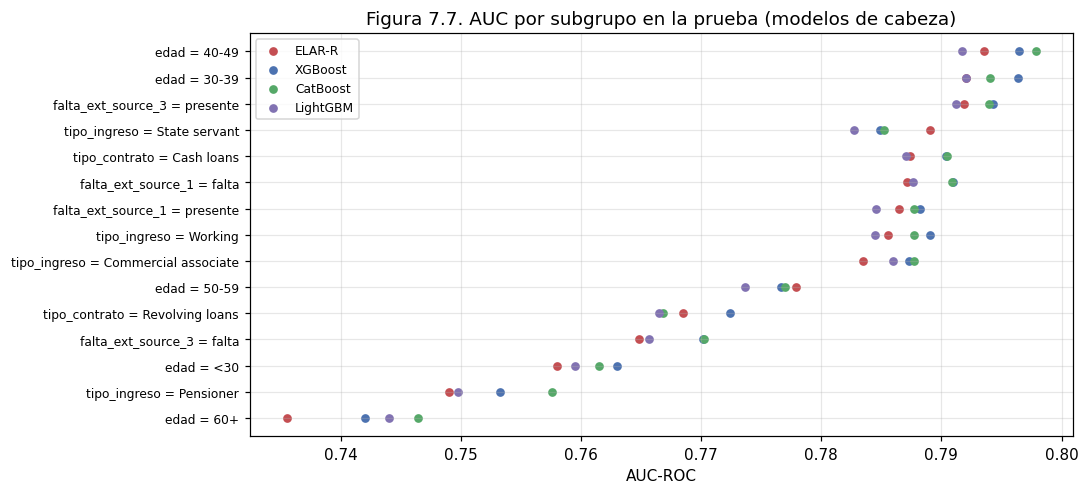

,n,tasa_mora,auc_elar,auc_xgboost,auc_catboost,auc_lightgbm,auc_logistica,dif_elar_menos_xgb,delong_p_holm
subgrupo,,,,,,,,,
falta_ext_source_1 = falta,34783,0.0850,0.7872,0.7909,0.7909,0.7876,0.7776,-0.0038,0.0211
falta_ext_source_1 = presente,26720,0.0752,0.7865,0.7882,0.7877,0.7846,0.7758,-0.0017,0.9279
falta_ext_source_3 = presente,49343,0.0773,0.7919,0.7943,0.7940,0.7912,0.7819,-0.0024,0.1879
falta_ext_source_3 = falta,12160,0.0945,0.7648,0.7702,0.7702,0.7657,0.7521,-0.0053,0.1326
tipo_contrato = Cash loans,55672,0.0835,0.7874,0.7904,0.7905,0.7871,0.7770,-0.0031,0.0202
tipo_contrato = Revolving loans,5831,0.0542,0.7685,0.7724,0.7668,0.7665,0.7543,-0.0039,0.9279
tipo_ingreso = Working,31731,0.0979,0.7856,0.7890,0.7877,0.7845,0.7747,-0.0035,0.0439
tipo_ingreso = State servant,4185,0.0538,0.7890,0.7849,0.7852,0.7827,0.7832,0.0041,0.9279
tipo_ingreso = Pensioner,11228,0.0550,0.7490,0.7533,0.7576,0.7498,0.7381,-0.0042,0.8805


In [13]:
S = pd.read_csv(F6 / "errores_subgrupo.csv")
S["subgrupo"] = S["grupo"] + " = " + S["nivel"].astype(str)
t = S.set_index("subgrupo")[["n", "tasa_mora", "auc_elar", "auc_xgboost", "auc_catboost", "auc_lightgbm", "auc_logistica", "dif_elar_menos_xgb", "delong_p_holm"]]
fig, ax = plt.subplots(figsize=(10, 4.6))
orden = t.sort_values("auc_elar").index
y = np.arange(len(orden))
for m in CABEZA:
    ax.scatter(t.loc[orden, f"auc_{m}"], y, color=COLOR[m], label=NOMBRE[m], s=22)
ax.set_yticks(y, orden, fontsize=8)
ax.set(title="Figura 7.7. AUC por subgrupo en la prueba (modelos de cabeza)", xlabel="AUC-ROC")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
t.round(4)

**Lectura de la figura 7.7.** Los cuatro modelos de cabeza fallan en los mismos lugares. Los mayores de 60 años, los pensionados, los
menores de 30, los clientes sin `EXT_SOURCE_3` y los créditos rotativos son los subgrupos más difíciles (AUC 0.73–0.77), y los de 30 a 49 años los más
fáciles (≈ 0.79). Es la paradoja que se anticipó en el capítulo 2: los mayores incumplen menos, pero es más difícil saber cuáles. ELAR-R
queda por debajo de XGBoost en 13 de los 15 subgrupos, aunque solo en 3 (falta de EXT_SOURCE_1, créditos de efectivo y asalariados) la
diferencia es significativa tras Holm. No se analizan sexo ni otras variables sensibles como eje (decisión ética, cap. 2).

## 7.12 Cómputo

In [14]:
tme = pd.read_csv(RAIZ / "resultados_e4" / "tabla_maestra_e4.csv", low_memory=False)
adic = tme[tme["fuente"].astype(str).str.startswith("E4 conjuntos")]
horas = (adic.groupby(["modelo", "conjunto"])["t_total_s"].sum().unstack() / 3600).rename(index=NOMBRE, columns=CONJ)
horas["total (h)"] = horas.sum(axis=1)
horas["s por ajuste con 60k filas (HC)"] = R[(R["estudio"] == "semillas") & (R["valor"] == 0)].set_index("modelo")["segundos"].rename(index=NOMBRE)
print("Equipo: un portatil con CPU Intel y GPU RTX 3050 (GPU solo para XGBoost, LightGBM y CatBoost); dos procesos en paralelo en F5.")
horas.sort_values("total (h)", ascending=False).round(2)

Equipo: un portatil con CPU Intel y GPU RTX 3050 (GPU solo para XGBoost, LightGBM y CatBoost); dos procesos en paralelo en F5.


conjunto,Bank marketing,German credit,Taiwan default,total (h),s por ajuste con 60k filas (HC)
modelo,,,,,
ELAR-R,7.73,0.21,2.91,10.85,1519.63
CatBoost,4.92,0.63,1.86,7.42,64.28
LightGBM,1.19,0.10,0.79,2.08,19.07
XGBoost,0.79,0.10,0.53,1.42,164.38
Random forest,0.27,0.07,0.34,0.68,79.20
Logistica,0.45,0.00,0.15,0.60,233.40
KNN,0.25,0.00,0.25,0.51,6.55
SVM,0.18,0.01,0.27,0.45,46.53
Arbol,0.03,0.00,0.03,0.06,28.44


**Lectura de la tabla 7.12.** ELAR-R es el modelo más caro de entrenar en los dos conjuntos grandes (Taiwan y Bank) y en Home Credit; en
German, con 1,000 filas, lo supera CatBoost. Entre los dos suman la mayor parte de las horas de la evaluación ampliada. Es el precio de su estabilidad y de su robustez al ruido en las etiquetas. Para el
dashboard no importa (la inferencia es rápida y el modelo ya está entrenado), pero sí para reentrenarlo con frecuencia.

## 7.13 Resumen

| Aspecto | Resultado para ELAR-R |
|---|---|
| Conjuntos adicionales (H2) | mejor en German y Taiwan; significativamente peor que CatBoost y LightGBM en Bank → **H2 rechazada** |
| Entre conjuntos | mejor rango medio (2.25), pero sin diferencia significativa con el boosting (N = 4) |
| Estabilidad (semillas) | la más alta de los modelos estocásticos, empatada con random forest (de = 0.0005) |
| Sensibilidad | la más baja (rango 0.002) |
| Ruido en etiquetas | pérdida pequeña (−0.005 con 10 % invertidas, frente a −0.011 a −0.015 del boosting; random forest −0.003) |
| Desbalance y ruido en entradas | similar a XGBoost y CatBoost, mejor que LightGBM |
| Calibración | buena sin recalibrar (ECE 0.004) |
| Subgrupos | mismos puntos débiles que el boosting; levemente por debajo de XGBoost |
| Cómputo | el más lento (≈ 9 veces XGBoost) |